# Malayalam Named Entity Recognition — 02. Model Training
Fine-tuning **IndicBERTv2** for Malayalam NER with two decoding heads:
1. **Linear (softmax) head** trained with inverse-frequency class-weighted cross-entropy.
2. **CRF head** trained with the CRF negative log-likelihood, which learns valid IOB2 tag transitions.

Training uses AdamW, a cosine schedule with 10% warm-up, and FP16 mixed precision on GPU.

## 0. Environment Setup
Works both **locally** (run from the project's `submission codes/` folder, which sits next to `dataset/` and `results/`) and on **Google Colab** (Runtime → Change runtime type → GPU).

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !pip -q install "datasets<4" seqeval pytorch-crf

# Project root = folder that contains dataset/ and results/
PROJECT_DIR = os.path.abspath("..") if os.path.isdir(os.path.join("..", "dataset")) else os.path.abspath(".")
print("Running in Colab:", IN_COLAB)
print("Project directory:", PROJECT_DIR)

Running in Colab: False
Project directory: E:\Downloads\SEM 7\NLP\Project


In [2]:
import torch
from transformers.utils import logging as hf_logging
from huggingface_hub.utils import disable_progress_bars, logging as hub_logging
hf_logging.set_verbosity_error(); hf_logging.disable_progress_bar()
hub_logging.set_verbosity_error(); disable_progress_bars()

# ---------------- Paths ----------------
DATA_DIR = os.path.join(PROJECT_DIR, "dataset")
TRAIN_CSV = os.path.join(DATA_DIR, "train.csv")
VAL_CSV = os.path.join(DATA_DIR, "validation.csv")
TEST_CSV = os.path.join(DATA_DIR, "test.csv")
MODEL_SAVE_DIR = os.path.join(PROJECT_DIR, "results", "malayalam_ner_model")          # IndicBERTv2 + Linear head
CRF_MODEL_SAVE_DIR = os.path.join(PROJECT_DIR, "results", "malayalam_ner_crf_model")  # IndicBERTv2 + CRF head

# ---------------- Hardware ----------------
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_FP16 = torch.cuda.is_available()

# ---------------- Model & labels (IOB2) ----------------
MODEL_NAME = "ai4bharat/IndicBERTv2-MLM-only"
ID2LABEL = {0: "O", 1: "B-PER", 2: "I-PER", 3: "B-ORG", 4: "I-ORG", 5: "B-LOC", 6: "I-LOC"}
LABEL2ID = {v: k for k, v in ID2LABEL.items()}
NUM_LABELS = len(ID2LABEL)
ENTITY_COLORS = {"PER": "#3B82F6", "ORG": "#10B981", "LOC": "#F59E0B",
                 "MISC": "#8B5CF6", "DATE": "#EC4899", "CARDINAL": "#06B6D4"}

# ---------------- Hyperparameters (used for the final models) ----------------
MAX_LENGTH = 128
BATCH_SIZE = 32 if torch.cuda.is_available() else 8
LEARNING_RATE = 3e-5
WEIGHT_DECAY = 0.01
EPOCHS = 3
SEED = 42
MAX_TRAIN_SAMPLES = 50000

print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU")
print("torch", torch.__version__)

Device: cuda | NVIDIA GeForce RTX 3050 6GB Laptop GPU
torch 2.6.0+cu124


**Dataset.** If `dataset/*.csv` is not present (e.g. on Colab), the Malayalam split of [Naamapadam](https://huggingface.co/datasets/ai4bharat/naamapadam) is downloaded from HuggingFace and exported to the same CSV format.

In [3]:
def ensure_dataset():
    if all(os.path.exists(p) for p in (TRAIN_CSV, VAL_CSV, TEST_CSV)):
        print("Dataset found in", DATA_DIR)
        return
    from datasets import load_dataset
    ds = load_dataset("ai4bharat/naamapadam", "ml", trust_remote_code=True)
    os.makedirs(DATA_DIR, exist_ok=True)
    for split, path in [("train", TRAIN_CSV), ("validation", VAL_CSV), ("test", TEST_CSV)]:
        df = ds[split].to_pandas()[["tokens", "ner_tags"]]
        df["tokens"] = df["tokens"].map(lambda x: str(list(x)))
        df["ner_tags"] = df["ner_tags"].map(lambda x: str([int(t) for t in x]))
        df.to_csv(path, index=False)
    print("Dataset downloaded and saved to", DATA_DIR)

ensure_dataset()

Dataset found in E:\Downloads\SEM 7\NLP\Project\dataset


### Run mode
The final models were trained with the full configuration (50,000 sentences × 3 epochs per head). That takes several hours on an RTX 3050, so by default this notebook runs a **short demonstration** of the same pipeline on a small subset and does **not** overwrite the final checkpoints. Set `DEMO_MODE = False` to reproduce full training.

In [4]:
DEMO_MODE = True

if DEMO_MODE:
    TRAIN_SAMPLES, VAL_SAMPLES, RUN_EPOCHS, SAVE_CHECKPOINTS = 8000, 500, 1, False
else:
    TRAIN_SAMPLES, VAL_SAMPLES, RUN_EPOCHS, SAVE_CHECKPOINTS = MAX_TRAIN_SAMPLES, None, EPOCHS, True
print(f"DEMO_MODE={DEMO_MODE}: {TRAIN_SAMPLES} train sentences, {RUN_EPOCHS} epoch(s), save checkpoints={SAVE_CHECKPOINTS}")

DEMO_MODE=True: 8000 train sentences, 1 epoch(s), save checkpoints=False


## 1. Dataset & Subword Alignment

In [5]:
import ast
import pandas as pd
from torch.utils.data import Dataset


def load_ner_dataframe(csv_path, max_samples=None):
    """Loads CSV containing string representation of tokens and ner_tags."""
    df = pd.read_csv(csv_path)
    if max_samples and max_samples < len(df):
        df = df.iloc[:max_samples].copy()

    processed_records = []
    for idx, row in df.iterrows():
        try:
            tokens = ast.literal_eval(row['tokens']) if isinstance(row['tokens'], str) else row['tokens']
            tags = ast.literal_eval(row['ner_tags']) if isinstance(row['ner_tags'], str) else row['ner_tags']
            if len(tokens) == len(tags) and len(tokens) > 0:
                processed_records.append({"tokens": tokens, "ner_tags": tags})
        except Exception:
            continue

    return processed_records


class MalayalamNERDataset(Dataset):
    """PyTorch Dataset with HuggingFace Fast Tokenizer Subword Alignment."""

    def __init__(self, records, tokenizer, max_length=MAX_LENGTH):
        self.records = records
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        record = self.records[idx]
        word_list = record['tokens']
        label_list = record['ner_tags']

        encoding = self.tokenizer(
            word_list,
            is_split_into_words=True,
            truncation=True,
            padding="max_length",
            max_length=self.max_length,
            return_tensors="pt"
        )

        word_ids = encoding.word_ids(batch_index=0)
        aligned_labels = []
        previous_word_idx = None

        for word_idx in word_ids:
            if word_idx is None:
                # Special tokens ([CLS], [SEP], [PAD]) get -100 label
                aligned_labels.append(-100)
            elif word_idx != previous_word_idx:
                # First subword token of the word gets original label
                aligned_labels.append(label_list[word_idx])
            else:
                # Subsequent subword tokens get -100 so loss ignored
                aligned_labels.append(-100)
            previous_word_idx = word_idx

        return {
            "input_ids": encoding["input_ids"].squeeze(0),
            "attention_mask": encoding["attention_mask"].squeeze(0),
            "labels": torch.tensor(aligned_labels, dtype=torch.long)
        }

## 2. Model Architectures

In [6]:
import torch.nn as nn
from transformers import AutoModelForTokenClassification, AutoConfig, AutoModel, AutoTokenizer
from torchcrf import CRF


class MalayalamBERTCRF(nn.Module):
    """Transformer sequence encoder topped with a Conditional Random Field (CRF) layer."""
    def __init__(self, model_name=MODEL_NAME, num_labels=NUM_LABELS):
        super().__init__()
        self.num_labels = num_labels
        self.config = AutoConfig.from_pretrained(model_name)
        self.bert = AutoModel.from_pretrained(model_name, config=self.config)
        self.dropout = nn.Dropout(self.config.hidden_dropout_prob)
        self.classifier = nn.Linear(self.config.hidden_size, num_labels)
        self.crf = CRF(num_labels, batch_first=True)

    def forward(self, input_ids, attention_mask, labels=None):
        outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        sequence_output = self.dropout(outputs[0])
        emissions = self.classifier(sequence_output)

        if labels is not None:
            # Valid positions = first subword of every word; [CLS] forced True for pytorch-crf
            mask = (labels != -100)
            mask[:, 0] = True
            clean_labels = labels.clone()
            clean_labels[clean_labels == -100] = 0
            loss = -self.crf(emissions, clean_labels, mask=mask, reduction='mean')
            return type('CRFOutput', (object,), {"loss": loss, "logits": emissions})()
        else:
            mask = (attention_mask == 1)
            preds = self.crf.decode(emissions, mask=mask)
            return type('CRFOutput', (object,), {"logits": emissions, "predictions": preds})()

    def save_pretrained(self, save_dir):
        os.makedirs(save_dir, exist_ok=True)
        torch.save(self.state_dict(), os.path.join(save_dir, "pytorch_model.bin"))
        self.config.save_pretrained(save_dir)

    def load_pretrained(self, save_dir):
        self.load_state_dict(torch.load(os.path.join(save_dir, "pytorch_model.bin"), map_location=DEVICE))


def build_ner_model(model_name=MODEL_NAME, num_labels=NUM_LABELS, use_crf=True):
    """Initializes standard Transformer token classifier or CRF-augmented model."""
    if use_crf:
        print("Configuring Model: IndicBERTv2 + Conditional Random Field (CRF) Head")
        return MalayalamBERTCRF(model_name=model_name, num_labels=num_labels)
    print("Configuring Model: IndicBERTv2 + Linear Token Classification Head")
    model_config = AutoConfig.from_pretrained(model_name, num_labels=num_labels,
                                              id2label=ID2LABEL, label2id=LABEL2ID)
    return AutoModelForTokenClassification.from_pretrained(model_name, config=model_config)

In [7]:
def get_class_weights(dataset_records, num_labels=NUM_LABELS):
    """Computes inverse class frequencies to handle O-tag imbalance."""
    counts = torch.zeros(num_labels)
    for record in dataset_records:
        for tag in record['ner_tags']:
            if 0 <= tag < num_labels:
                counts[tag] += 1
    total = counts.sum()
    weights = total / (num_labels * (counts + 1e-5))
    weights = weights / weights.max()  # Normalize
    return weights.to(DEVICE)

## 3. Validation Loop (entity-level seqeval metrics)

In [8]:
import time
from torch.utils.data import DataLoader
from transformers import get_cosine_schedule_with_warmup
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score


def format_time(seconds):
    m, s = divmod(int(seconds), 60)
    h, m = divmod(m, 60)
    return f"{h:02d}:{m:02d}:{s:02d}" if h > 0 else f"{m:02d}:{s:02d}"


def decode_batch(model, batch, use_crf):
    """Returns word-level (gold, predicted) tag sequences for one batch."""
    input_ids = batch["input_ids"].to(DEVICE)
    attention_mask = batch["attention_mask"].to(DEVICE)
    targets = batch["labels"].numpy()
    if use_crf:
        preds = model(input_ids=input_ids, attention_mask=attention_mask).predictions
    else:
        preds = model(input_ids=input_ids, attention_mask=attention_mask).logits.argmax(-1).cpu().tolist()
    gold, pred = [], []
    for i in range(len(targets)):
        sl, sp = [], []
        for j in range(len(targets[i])):
            if targets[i][j] != -100 and j < len(preds[i]):
                sl.append(ID2LABEL[int(targets[i][j])]); sp.append(ID2LABEL[int(preds[i][j])])
        gold.append(sl); pred.append(sp)
    return gold, pred


def evaluate_model(model, val_loader, use_crf):
    model.eval()
    all_labels, all_preds = [], []
    with torch.no_grad():
        for batch in val_loader:
            g, p = decode_batch(model, batch, use_crf)
            all_labels += g; all_preds += p
    return (precision_score(all_labels, all_preds), recall_score(all_labels, all_preds),
            f1_score(all_labels, all_preds), all_labels, all_preds)

## 4. Training Loop

In [9]:
def train(use_crf, train_records, val_records, epochs, save_dir=None):
    torch.manual_seed(SEED)
    name = "CRF" if use_crf else "Linear"
    print("=" * 60)
    print(f"Training IndicBERTv2 + {name} head | device={DEVICE} | fp16={USE_FP16}")
    print("=" * 60)

    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
    train_loader = DataLoader(MalayalamNERDataset(train_records, tokenizer), batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(MalayalamNERDataset(val_records, tokenizer), batch_size=BATCH_SIZE, shuffle=False)

    model = build_ner_model(use_crf=use_crf).to(DEVICE)
    criterion = nn.CrossEntropyLoss(weight=get_class_weights(train_records), ignore_index=-100)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    total_steps = len(train_loader) * epochs
    scheduler = get_cosine_schedule_with_warmup(optimizer, int(total_steps * 0.1), total_steps)
    scaler = torch.amp.GradScaler("cuda") if USE_FP16 else None

    history = {"step_loss": [], "epoch": []}
    best_f1, t0 = 0.0, time.time()
    for epoch in range(1, epochs + 1):
        model.train(); running = 0.0; te = time.time()
        LOG_EVERY = 50
        for step, batch in enumerate(train_loader, 1):
            optimizer.zero_grad()
            input_ids = batch["input_ids"].to(DEVICE)
            attention_mask = batch["attention_mask"].to(DEVICE)
            labels = batch["labels"].to(DEVICE)
            with torch.amp.autocast("cuda", enabled=USE_FP16):
                if use_crf:
                    loss = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels).loss
                else:
                    logits = model(input_ids=input_ids, attention_mask=attention_mask).logits
                    loss = criterion(logits.view(-1, NUM_LABELS), labels.view(-1))
            if scaler is not None:
                scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
            else:
                loss.backward(); optimizer.step()
            scheduler.step()
            running += loss.item(); history["step_loss"].append(loss.item())
            if step % LOG_EVERY == 0 or step == len(train_loader):
                print(f"  epoch {epoch} step {step:>5}/{len(train_loader)} | avg loss {running / step:.4f} | elapsed {format_time(time.time() - te)}")

        p, r, f1, _, _ = evaluate_model(model, val_loader, use_crf)
        history["epoch"].append({"epoch": epoch, "train_loss": running / len(train_loader), "val_P": p, "val_R": r, "val_F1": f1})
        print(f"Epoch {epoch}: time {format_time(time.time() - te)} | train loss {running / len(train_loader):.4f} "
              f"| val P {p:.4f} R {r:.4f} F1 {f1:.4f}")
        if save_dir and (f1 > best_f1 or epoch == 1):
            best_f1 = f1
            model.save_pretrained(save_dir); tokenizer.save_pretrained(save_dir)
            print(f"Saved best checkpoint to {save_dir} (F1 {f1:.4f})")
        best_f1 = max(best_f1, f1)
    print(f"Done in {format_time(time.time() - t0)} | best val F1 {best_f1:.4f}\n")
    return model, history

## 5. Run Training

In [10]:
train_records = load_ner_dataframe(TRAIN_CSV, max_samples=TRAIN_SAMPLES)
val_records = load_ner_dataframe(VAL_CSV, max_samples=VAL_SAMPLES)
print(f"Train: {len(train_records)} sentences | Validation: {len(val_records)} sentences")

w = get_class_weights(train_records).cpu()
pd.DataFrame({"tag": [ID2LABEL[i] for i in range(NUM_LABELS)], "class weight": w.numpy().round(4)}).set_index("tag").T

Train: 8000 sentences | Validation: 500 sentences


tag,O,B-PER,I-PER,B-ORG,I-ORG,B-LOC,I-LOC
class weight,0.0117,0.1088,0.1344,0.2381,0.3349,0.1864,1.0


In [11]:
import gc
model, hist_linear = train(False, train_records, val_records, RUN_EPOCHS,
                           save_dir=MODEL_SAVE_DIR if SAVE_CHECKPOINTS else None)
del model; gc.collect(); torch.cuda.empty_cache()

Training IndicBERTv2 + Linear head | device=cuda | fp16=True


Configuring Model: IndicBERTv2 + Linear Token Classification Head


  epoch 1 step    50/250 | avg loss 1.8366 | elapsed 01:08


  epoch 1 step   100/250 | avg loss 1.4094 | elapsed 02:17


  epoch 1 step   150/250 | avg loss 1.1503 | elapsed 03:28


  epoch 1 step   200/250 | avg loss 1.0012 | elapsed 04:36


  epoch 1 step   250/250 | avg loss 0.9284 | elapsed 05:45


Epoch 1: time 05:48 | train loss 0.9284 | val P 0.4637 R 0.6857 F1 0.5532
Done in 05:48 | best val F1 0.5532



In [12]:
model, hist_crf = train(True, train_records, val_records, RUN_EPOCHS,
                        save_dir=CRF_MODEL_SAVE_DIR if SAVE_CHECKPOINTS else None)

Training IndicBERTv2 + CRF head | device=cuda | fp16=True


Configuring Model: IndicBERTv2 + Conditional Random Field (CRF) Head


  epoch 1 step    50/250 | avg loss 12.6963 | elapsed 01:07


  epoch 1 step   100/250 | avg loss 9.3452 | elapsed 02:20


  epoch 1 step   150/250 | avg loss 7.6786 | elapsed 03:34


  epoch 1 step   200/250 | avg loss 6.6942 | elapsed 04:48


  epoch 1 step   250/250 | avg loss 6.0537 | elapsed 06:03


Epoch 1: time 06:06 | train loss 6.0537 | val P 0.6713 R 0.6531 F1 0.6621
Done in 06:06 | best val F1 0.6621



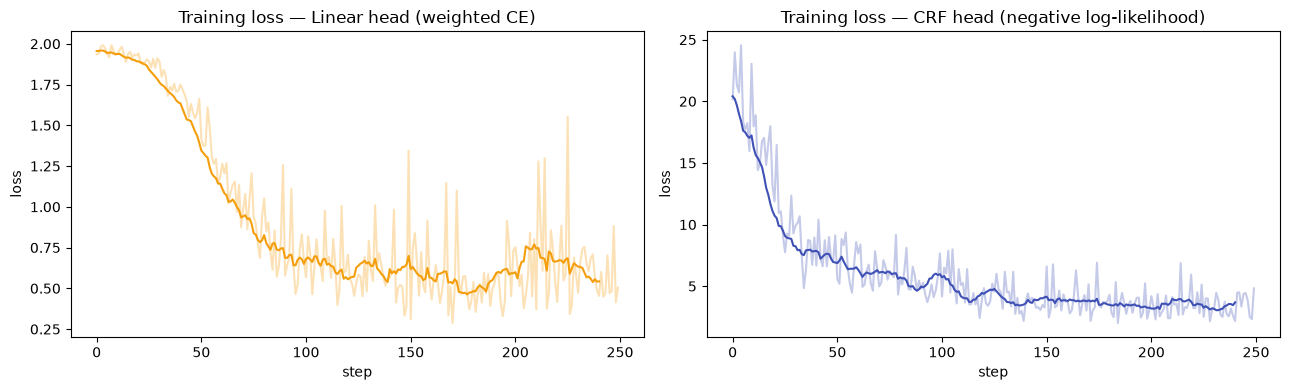

,epoch,train_loss,val_P,val_R,val_F1
head,,,,,
Linear,1,0.9284,0.4637,0.6857,0.5532
CRF,1,6.0537,0.6713,0.6531,0.6621


In [13]:
import matplotlib.pyplot as plt
import numpy as np

def smooth(x, k=10):
    return np.convolve(x, np.ones(k) / k, mode="valid")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (name, h, c) in zip(axes, [("Linear head (weighted CE)", hist_linear, "#F59E0B"), ("CRF head (negative log-likelihood)", hist_crf, "#3f51b5")]):
    ax.plot(h["step_loss"], alpha=.3, color=c); ax.plot(smooth(h["step_loss"]), color=c)
    ax.set_title(f"Training loss — {name}"); ax.set_xlabel("step"); ax.set_ylabel("loss")
plt.tight_layout(); plt.show()

pd.DataFrame([{"head": "Linear", **hist_linear["epoch"][-1]}, {"head": "CRF", **hist_crf["epoch"][-1]}]).set_index("head").round(4)

### Quick check: predictions from the CRF model trained above

In [14]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
demo = MalayalamNERDataset(val_records[:3], tokenizer)
batch = {k: torch.stack([demo[i][k] for i in range(len(demo))]) for k in demo[0]}
model.eval()
with torch.no_grad():
    gold, pred = decode_batch(model, batch, use_crf=True)
for rec, g, p in zip(val_records[:3], gold, pred):
    print(" ".join(f"{w}/{t}" if t != "O" else w for w, t in zip(rec["tokens"], p)))

" IMSUB ( 1.2 . " " 3.4 + 5i " " ) നൽകുന്നതു് " " - 2.2 - 5i " " "
ബാരാഹി/B-PER , അമരേശ്രാസ്/B-PER , ലക്ഷ്മിനാരായണൻ/B-PER എന്നിവർക്ക് സമർപ്പിച്ചിരിക്കുന്ന ഇവിടത്തെ അമ്പലങ്ങൾ പ്രശസ്തമാണ്
നമ്മുടെ സംസ്ഥാനത്തു നിന്നുള്ള ഒരാളെ രാജസ്ഥാനിൽ/B-LOC ജീവനോടെ ചുട്ടെരിച്ചു .


## Summary
- Both heads train end-to-end on the same IndicBERTv2 encoder.
- In this short demo the model only saw a few thousand sentences; the **final models** (50k sentences, 3 epochs) are evaluated in `03_Evaluation_Comparison.ipynb`.